In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image
from keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input 
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from keras import callbacks

In [2]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [3]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(Flatten())
model.add(Dense(10, activation='relu'))
model.add(Dense(10, activation='relu'))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='binary_crossentropy', 
              metrics=[
                      tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                      tf.keras.metrics.Precision(name="precision"),
                      tf.keras.metrics.Recall(name="recall"),
                      tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
                      tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
                      tf.keras.metrics.AUC(curve="PR", name="pr_auc")
                  ])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
results = model.evaluate(test_dataset, return_dict=True)
print(results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 68s 968ms/step - accuracy: 0.4932 - f1: 0.4900 - loss: 226.6844 - pr_auc: 0.5067 - precision: 0.5049 - recall: 0.4760 - roc_auc: 0.4896 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 3.4505 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 40s 675ms/step - accuracy: 0.5052 - f1: 0.5116 - loss: 2.5555 - pr_auc: 0.5079 - precision: 0.5167 - recall: 0.5066 - roc_auc: 0.4933 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 2.6947 - val_pr_auc: 0.5597 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5579
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 37s 596ms/step - accuracy: 0.5021 - f1: 0.5303 - loss: 2.2534 - pr_auc: 0.5196 - precision: 0.5124 - recall: 0.5495 - roc_auc: 0.5034 - val_accuracy: 0.4749 - val_f1: 0.0000e+00 - val_loss: 3.8784 - val_pr_auc: 0.5251 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.5000
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━

In [ ]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(16, kernel_size=3, 
                 activation='relu', 
                 padding='same'))
model.add(BatchNormalization())
model.add(MaxPool2D(2))
model.add(Conv2D(32, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Conv2D(64, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
        tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
custom_model_results = model.evaluate(test_dataset, return_dict=True)
print(results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 184s 3s/step - accuracy: 0.6729 - f1: 0.7107 - loss: 0.9259 - pr_auc: 0.6951 - precision: 0.6489 - recall: 0.7855 - roc_auc: 0.7294 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 5.4180 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 203s 3s/step - accuracy: 0.9112 - f1: 0.9135 - loss: 0.2112 - pr_auc: 0.9762 - precision: 0.9098 - recall: 0.9173 - roc_auc: 0.9744 - val_accuracy: 0.5272 - val_f1: 0.6896 - val_loss: 4.0304 - val_pr_auc: 0.5628 - val_precision: 0.5262 - val_recall: 1.0000 - val_roc_auc: 0.5705
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 293s 4s/step - accuracy: 0.9744 - f1: 0.9751 - loss: 0.0735 - pr_auc: 0.9979 - precision: 0.9688 - recall: 0.9816 - roc_auc: 0.9977 - val_accuracy: 0.8033 - val_f1: 0.8423 - val_loss: 0.4424 - val_pr_auc: 0.9958 - val_precision: 0.7275 - val_recall: 1.0000 - val_roc_auc: 0.9976
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - ac

In [ ]:
custom_model_results = model.evaluate(test_dataset, return_dict=True)
print(custom_model_results)

In [ ]:
model.save("../models/custom_model.keras")
baseline_model = load_model("../models/custom_model.keras")
baseline_model.summary()
model.count_params()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        50,177 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,413 (864.90 KB)

 Trainable params: 73,793 (288.25 KB)

 Non-trainable params: 32 (128.00 B)

 Optimizer params: 147,588 (576.52 KB)

73825

In [ ]:
path = Path("../models/custom_model.keras")
custom_model_file_size = round(path.stat().st_size / (1024**2),2)
custom_model_params = model.count_params()

File size: 0.89 MB


In [ ]:
print(train_dataset.class_names)

['flip', 'notflip']


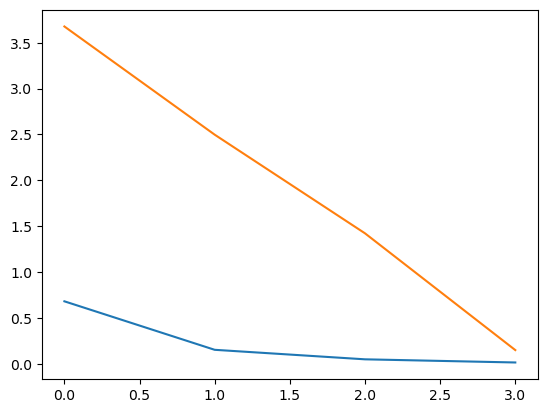

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [ ]:
resnet50_base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep its pretrained weights fixed
resnet50_base_model.trainable = False

resnet50_model = Sequential()
resnet50_model.add(Input(shape=(224, 224, 3)))
resnet50_model.add(tf.keras.layers.Lambda(preprocess_input))
resnet50_model.add(resnet50_base_model)
resnet50_model.add(GlobalAveragePooling2D())
resnet50_model.add(Dense(1, activation="sigmoid"))

resnet50_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

resnet50_model_history = resnet50_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 785s 12s/step - accuracy: 0.5235 - f1: 0.5220 - loss: 0.6917 - pr_auc: 0.5458 - precision: 0.5361 - recall: 0.5087 - roc_auc: 0.5532 - val_accuracy: 0.5900 - val_f1: 0.7057 - val_loss: 0.6795 - val_pr_auc: 0.7119 - val_precision: 0.5663 - val_recall: 0.9363 - val_roc_auc: 0.6878
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.5909 - f1: 0.6743 - loss: 0.6732 - pr_auc: 0.6619 - precision: 0.5737 - recall: 0.8314 - roc_auc: 0.6692 

In [ ]:
resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
print(resnet50_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 131s 7s/step - accuracy: 0.9631 - f1: 0.9647 - loss: 0.1461 - pr_auc: 0.9967 - precision: 0.9495 - recall: 0.9805 - roc_auc: 0.9965       
{'accuracy': 0.9631490707397461, 'f1': 0.9647434949874878, 'loss': 0.1461319476366043, 'pr_auc': 0.9966897964477539, 'precision': 0.9495267868041992, 'recall': 0.9804560542106628, 'roc_auc': 0.9964618682861328}


In [ ]:
resnet50_model.save("../models/resnet50_model.keras")
path = Path("../models/resnet50_model.keras")
restnet50_file_size = round(path.stat().st_size / (1024**2),2)
restnet50_params = resnet50_model.count_params()

File size: 90.63 MB


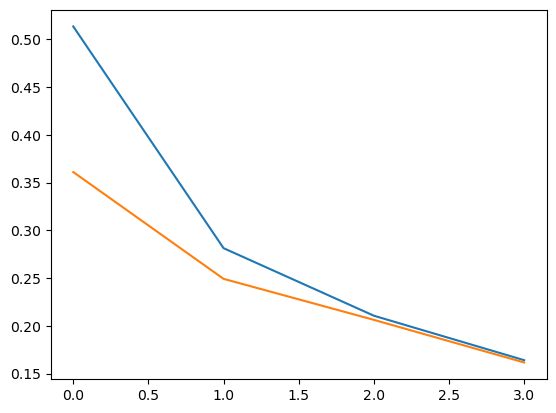

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_base_model.trainable = False

vgg16_model = Sequential()
vgg16_model.add(Input(shape=(224, 224, 3)))
vgg16_model.add(tf.keras.layers.Lambda(preprocess_input))
vgg16_model.add(vgg16_base_model)
vgg16_model.add(GlobalAveragePooling2D())
vgg16_model.add(Dense(1, activation="sigmoid"))

vgg16_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_model_history = vgg16_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
print(vgg16_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1966s 33s/step - accuracy: 0.5569 - f1: 0.5569 - loss: 1.1265 - pr_auc: 0.5797 - precision: 0.5701 - recall: 0.5444 - roc_auc: 0.5624 - val_accuracy: 0.6444 - val_f1: 0.6256 - val_loss: 0.7610 - val_pr_auc: 0.6772 - val_precision: 0.6995 - val_recall: 0.5657 - val_roc_auc: 0.6955
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 2101s 35s/step - accuracy: 0.7189 - f1: 0.7204 - loss: 0.6143 - pr_auc: 0.7653 - precision: 0.7333 - recall: 0.7079 - roc_auc: 0.7760 - val_accuracy: 0.8138 - val_f1: 0.8318 - val_loss: 0.4628 - val_pr_auc: 0.8630 - val_precision: 0.7914 - val_recall: 0.8765 - val_roc_auc: 0.8675
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1861s 31s/step - accuracy: 0.8166 - f1: 0.8225 - loss: 0.4243 - pr_auc: 0.8833 - precision: 0.8146 - recall: 0.8304 - roc_auc: 0.8873 - val_accuracy: 0.8766 - val_f1: 0.8889 - val_loss: 0.3317 - val_pr_auc: 0.9390 - val_precision: 0.8429 - val_recall: 0.9402 - val_roc_auc: 0.9381
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1796s 30s

NameError: name 'model' is not defined

In [ ]:
vgg16_model_results = vgg16_model.evaluate(test_dataset, return_dict=True)
print(vgg16_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 459s 24s/step - accuracy: 0.8660 - f1: 0.8662 - loss: 0.3194 - pr_auc: 0.9410 - precision: 0.8900 - recall: 0.8436 - roc_auc: 0.9429        
{'accuracy': 0.8659966588020325, 'f1': 0.8662206530570984, 'loss': 0.3193870782852173, 'pr_auc': 0.9409991502761841, 'precision': 0.8900343775749207, 'recall': 0.8436481952667236, 'roc_auc': 0.9429124593734741}


In [ ]:
vgg16_model.save("../models/vgg16_model.keras")
path = Path("../models/vgg16_model.keras")
vgg16_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_params = vgg16_model.count_params()

File size: 56.22 MB


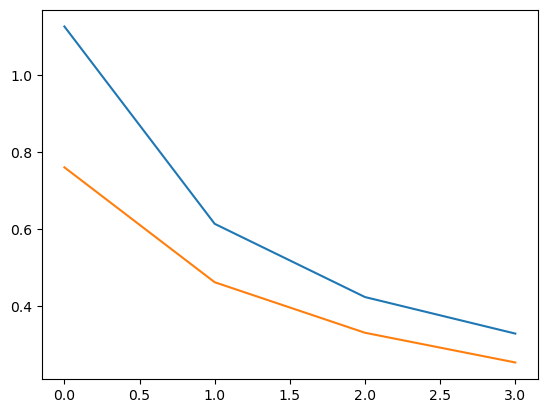

In [ ]:
plt.plot(vgg16_model_history.history['loss'])
plt.plot(vgg16_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

augmentation_model = Sequential([
    #tf.keras.layers.RandomRotation(0.02),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

vgg16_base_model.trainable = False

vgg16_aug_model = Sequential()
vgg16_aug_model.add(Input(shape=(224, 224, 3)))
vgg16_aug_model.add(augmentation_model)
vgg16_aug_model.add(tf.keras.layers.Lambda(preprocess_input))
vgg16_aug_model.add(vgg16_base_model)
vgg16_aug_model.add(GlobalAveragePooling2D())
vgg16_aug_model.add(Dense(1, activation="sigmoid"))

vgg16_aug_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_aug_model_history = vgg16_aug_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_aug_model_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
print(vgg16_aug_model_results)

In [ ]:
vgg16_aug_model.save("../models/vgg16_aug_model.keras")
path = Path("../models/vgg16_aug_model.keras")
vgg16_aug_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_aug_model_params = vgg16_aug_model.count_params()

In [ ]:
efficientnetb0_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnetb0_base_model.trainable = False

efficientnetb0_model = Sequential()
efficientnetb0_model.add(Input(shape=(224, 224, 3)))
efficientnetb0_model.add(efficientnetb0_base_model)
efficientnetb0_model.add(GlobalAveragePooling2D())
efficientnetb0_model.add(Dense(1, activation="sigmoid"))

efficientnetb0_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
efficientnetb0_model_history = efficientnetb0_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
print(efficientnetb0_results)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 438s 7s/step - accuracy: 0.6661 - f1: 0.6918 - loss: 0.6136 - pr_auc: 0.7022 - precision: 0.6554 - recall: 0.7324 - roc_auc: 0.7316 - val_accuracy: 0.8347 - val_f1: 0.8597 - val_loss: 0.5104 - val_pr_auc: 0.8735 - val_precision: 0.7756 - val_recall: 0.9641 - val_roc_auc: 0.9047
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 352s 6s/step - accuracy: 0.8464 - f1: 0.8599 - loss: 0.4613 - pr_auc: 0.9126 - precision: 0.8061 - recall: 0.9213 - roc_auc: 0.9232 - val_accuracy: 0.8975 - val_f1: 0.9070 - val_loss: 0.4028 - val_pr_auc: 0.9654 - val_precision: 0.8659 - val_recall: 0.9522 - val_roc_auc: 0.9676
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 309s 5s/step - accuracy: 0.8887 - f1: 0.8972 - loss: 0.3808 - pr_auc: 0.9548 - precision: 0.8507 - recall: 0.9489 - roc_auc: 0.9570 - val_accuracy: 0.9079 - val_f1: 0.9179 - val_loss: 0.3394 - val_pr_auc: 0.9801 - val_precision: 0.8632 - val_recall: 0.9801 - val_roc_auc: 0.9791
E

In [ ]:
efficientnetb0_model.save("../models/efficientnetb0_model.keras")
path = Path("../models/efficientnetb0_model.keras")
efficientnetb0_file_size = round(path.stat().st_size / (1024**2),2)
efficientnetb0_params = efficientnetb0_model.count_params()

File size: 16.27 MB


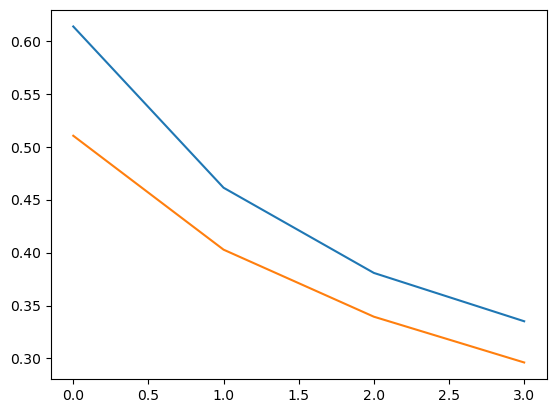

In [ ]:
plt.plot(efficientnetb0_model_history.history['loss'])
plt.plot(efficientnetb0_model_history.history['val_loss'])

plt.show()

In [ ]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = False

mobilenetv2_model = Sequential()
mobilenetv2_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_model.add(tf.keras.layers.Lambda(preprocess_input))
mobilenetv2_model.add(mobilenetv2_base_model)
mobilenetv2_model.add(GlobalAveragePooling2D())
mobilenetv2_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
mobilenetv2_model_history = mobilenetv2_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_results)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 304s 5s/step - accuracy: 0.7017 - f1: 0.7152 - loss: 0.5674 - pr_auc: 0.7785 - precision: 0.6988 - recall: 0.7324 - roc_auc: 0.7810 - val_accuracy: 0.7657 - val_f1: 0.7879 - val_loss: 0.4941 - val_pr_auc: 0.8830 - val_precision: 0.7509 - val_recall: 0.8287 - val_roc_auc: 0.8660
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 251s 4s/step - accuracy: 0.8333 - f1: 0.8429 - loss: 0.4206 - pr_auc: 0.9171 - precision: 0.8137 - recall: 0.8744 - roc_auc: 0.9165 - val_accuracy: 0.7929 - val_f1: 0.8278 - val_loss: 0.4298 - val_pr_auc: 0.9344 - val_precision: 0.7346 - val_recall: 0.9482 - val_roc_auc: 0.9232
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 242s 4s/step - accuracy: 0.8689 - f1: 0.8763 - loss: 0.3586 - pr_auc: 0.9445 - precision: 0.8467 - recall: 0.9081 - roc_auc: 0.9445 - val_accuracy: 0.8577 - val_f1: 0.8722 - val_loss: 0.3585 - val_pr_auc: 0.9555 - val_precision: 0.8256 - val_recall: 0.9243 - val_roc_auc: 0.9481
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 161s 3s/step -

In [ ]:
mobilenetv2_model.save("../models/mobilenetv2_model.keras")
path = Path("../models/mobilenetv2_model.keras")
mobilenetv2_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_params = mobilenetv2_model.count_params()

File size: 9.19 MB


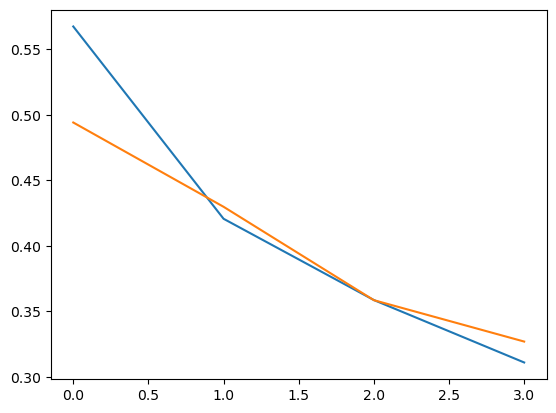

In [ ]:
plt.plot(mobilenetv2_model_history.history['loss'])
plt.plot(mobilenetv2_model_history.history['val_loss'])

plt.show()

In [ ]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = True


for layer in mobilenetv2_base_model.layers[:-20]:
    layer.trainable = False


mobilenetv2_tuned_model = Sequential()
mobilenetv2_tuned_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_tuned_model.add(tf.keras.layers.Lambda(preprocess_input))
mobilenetv2_tuned_model.add(mobilenetv2_base_model)
mobilenetv2_tuned_model.add(GlobalAveragePooling2D())
mobilenetv2_tuned_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_tuned_model.compile(
    optimizer= tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

earlystopping = callbacks.EarlyStopping(monitor="val_loss",
                                        mode="min",
                                        patience=3,
                                        restore_best_weights=True)


mobilenetv2_tuned_model_history = mobilenetv2_tuned_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks = [earlystopping]

)

Epoch 1/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 389s 5s/step - accuracy: 0.7706 - f1: 0.7775 - loss: 0.5312 - pr_auc: 0.8381 - precision: 0.7716 - recall: 0.7835 - roc_auc: 0.8459 - val_accuracy: 0.7469 - val_f1: 0.7206 - val_loss: 0.5437 - val_pr_auc: 0.8905 - val_precision: 0.8571 - val_recall: 0.6215 - val_roc_auc: 0.8856
Epoch 2/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 294s 4s/step - accuracy: 0.9138 - f1: 0.9177 - loss: 0.3447 - pr_auc: 0.9728 - precision: 0.8967 - recall: 0.9397 - roc_auc: 0.9730 - val_accuracy: 0.8661 - val_f1: 0.8667 - val_loss: 0.4336 - val_pr_auc: 0.9597 - val_precision: 0.9083 - val_recall: 0.8287 - val_roc_auc: 0.9552
Epoch 3/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 299s 5s/step - accuracy: 0.9488 - f1: 0.9509 - loss: 0.2477 - pr_auc: 0.9894 - precision: 0.9340 - recall: 0.9683 - roc_auc: 0.9894 - val_accuracy: 0.9079 - val_f1: 0.9113 - val_loss: 0.3576 - val_pr_auc: 0.9779 - val_precision: 0.9224 - val_recall: 0.9004 - val_roc_auc: 0.9754
Epoch 4/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 312s 5s/step - 

In [ ]:
mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_tuned_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 76s 4s/step - accuracy: 0.9380 - f1: 0.9398 - loss: 0.2610 - pr_auc: 0.9856 - precision: 0.9383 - recall: 0.9414 - roc_auc: 0.9857       
{'accuracy': 0.9380234479904175, 'f1': 0.9398373961448669, 'loss': 0.2610260546207428, 'pr_auc': 0.9855704307556152, 'precision': 0.9383116960525513, 'recall': 0.9413681030273438, 'roc_auc': 0.9857351779937744}


In [ ]:
mobilenetv2_tuned_model.save("../models/mobilenetv2_tuned_model.keras")
path = Path("../models/mobilenetv2_tuned_model.keras")
mobilenetv2_tuned_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_tuned_params = mobilenetv2_tuned_model.count_params()

File size: 9.19 MB


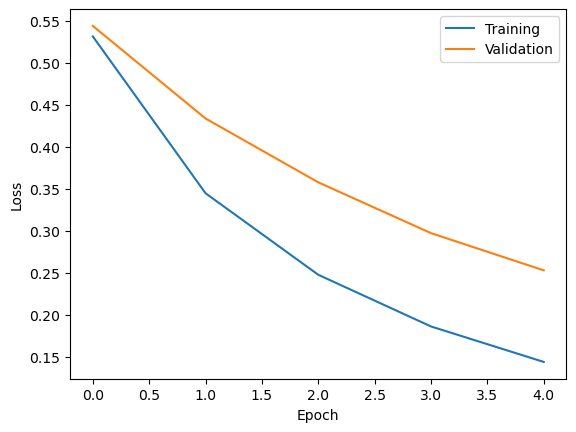

In [ ]:
plt.plot(mobilenetv2_tuned_model_history.history['loss'], label="Training")
plt.plot(mobilenetv2_tuned_model_history.history['val_loss'], label ="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.show()

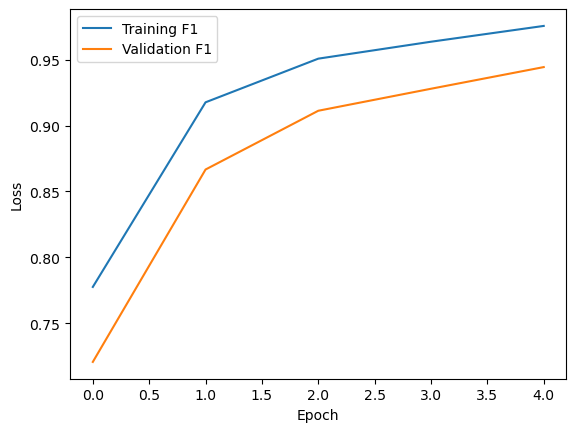

In [ ]:
plt.plot(mobilenetv2_tuned_model_history.history["f1"], label="Training F1")
plt.plot(mobilenetv2_tuned_model_history.history["val_f1"], label="Validation F1")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
comparsion_table = pd.DataFrame({
    "Model": ["Custom_Model", "ResNet50", "VGG16", "VGG16_Aug", "EfficientnetB0", "MobilenetV2", "MobilenetV2_tuned"],
    "Accuracy": [custom_model_results["accuracy"], resnet50_results["accuracy"], vgg16_model_results["accuracy"], vgg16_aug_model_results["accuracy"], efficientnetb0_results["accuracy"], mobilenetv2_results["accuracy"], mobilenetv2_tuned_results["accuracy"]],
    "Recall": [custom_model_results["recall"], resnet50_results["recall"], vgg16_model_results["recall"], vgg16_aug_model_results["recall"], efficientnetb0_results["recall"], mobilenetv2_results["recall"], mobilenetv2_tuned_results["recall"]],
    "Precision": [custom_model_results["precision"], resnet50_results["precision"], vgg16_model_results["precision"], vgg16_aug_model_results["precision"], efficientnetb0_results["precision"], mobilenetv2_results["precision"], mobilenetv2_tuned_results["precision"]],
    "ROC_AUC": [custom_model_results["roc_auc"], resnet50_results["roc_auc"], vgg16_model_results["roc_auc"], vgg16_aug_model_results["roc_auc"], efficientnetb0_results["roc_auc"], mobilenetv2_results["roc_auc"], mobilenetv2_tuned_results["roc_auc"]],
    "PR_AUC": [custom_model_results["pr_auc"], resnet50_results["pr_auc"], vgg16_model_results["pr_auc"], vgg16_aug_model_results["pr_auc"], efficientnetb0_results["pr_auc"], mobilenetv2_results["pr_auc"], mobilenetv2_tuned_results["pr_auc"]],
    "File_Size_MB": [custom_model_file_size, resnet50_file_size, vgg16_file_size, vgg16_aug_file_size, efficientnetb0_file_size, mobilenetv2_file_size, mobilenetv2_tuned_file_size],
    "Parameters": [custom_model_params, resnet50_params, vgg16_params, vgg16_aug_params, efficientnetb0_params, mobilenetv2_params, mobilenetv2_tuned_params]
})